# Black-Scholes calculator with Greeks, payoff and automatic analysis

This notebook calculates the price of a European option, the Greeks, interprets them automatically and says if the option is ITM, ATM or OTM. It also includes a continuous dividend yield (q) and some checks to be sure the formulas are correct.

Derivatives course, Universidad EIA.

In [1]:
# We import the libraries we need
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

sns.set_theme(style="whitegrid")

## Part 1. Black-Scholes function with price and Greeks

In [2]:
def black_scholes_greeks(S, K, T, r, sigma, tipo="call", q=0.0):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if tipo == "call":
        precio = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
        delta = np.exp(-q * T) * norm.cdf(d1)
        theta = (-S * np.exp(-q * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2)
                 + q * S * np.exp(-q * T) * norm.cdf(d1)) / 365
        rho = K * T * np.exp(-r * T) * norm.cdf(d2) / 100
    else:
        precio = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
        delta = -np.exp(-q * T) * norm.cdf(-d1)
        theta = (-S * np.exp(-q * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) + r * K * np.exp(-r * T) * norm.cdf(-d2)
                 - q * S * np.exp(-q * T) * norm.cdf(-d1)) / 365
        rho = -K * T * np.exp(-r * T) * norm.cdf(-d2) / 100
    gamma = np.exp(-q * T) * norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega = S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T) / 100
    return {"price": precio, "delta": delta, "gamma": gamma, "vega": vega, "theta": theta, "rho": rho}

## Part 2. Automatic interpretation and ITM/ATM/OTM

In [3]:
def interpret_greeks(g):
    return [
        f"Delta {g['delta']:.4f}: sensitivity of the price to the underlying. Delta close to 0.5 means ATM.",
        f"Gamma {g['gamma']:.4f}: sensitivity of delta to the underlying. High gamma near expiry means ATM.",
        f"Vega {g['vega']:.4f}: the option gains {g['vega']:.4f} for each 1% more of volatility. High for ATM options with long expiry.",
        f"Theta {g['theta']:.4f}: the option loses {abs(g['theta']):.4f} per day. More negative means faster time decay.",
        f"Rho {g['rho']:.4f}: change for 1% more in the risk-free rate. More relevant for long expiries.",
    ]

def classify_option(S, K, tipo):
    if S == K:
        return "ATM"
    if tipo == "call":
        return "ITM" if S > K else "OTM"
    return "ITM" if S < K else "OTM"

## Part 3. Example

In [4]:
# Base parameters
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
tipo = "call"

g = black_scholes_greeks(S, K, T, r, sigma, tipo)
print({k: float(round(v, 4)) for k, v in g.items()})
for linea in interpret_greeks(g):
    print("-", linea)
print("The option is:", classify_option(S, K, tipo))

{'price': 10.4506, 'delta': 0.6368, 'gamma': 0.0188, 'vega': 0.3752, 'theta': -0.0176, 'rho': 0.5323}
- Delta 0.6368: sensitivity of the price to the underlying. Delta close to 0.5 means ATM.
- Gamma 0.0188: sensitivity of delta to the underlying. High gamma near expiry means ATM.
- Vega 0.3752: the option gains 0.3752 for each 1% more of volatility. High for ATM options with long expiry.
- Theta -0.0176: the option loses 0.0176 per day. More negative means faster time decay.
- Rho 0.5323: change for 1% more in the risk-free rate. More relevant for long expiries.
The option is: ATM


## Part 4. Checks

To be sure the formulas are right:
1. The call price with S = K = 100, T = 1, r = 5%, sigma = 20% must be 10.4506 (the classic example of Hull).
2. Put-call parity: C - P = S e^(-qT) - K e^(-rT).
3. Each Greek must be equal to the numerical derivative of the price (finite differences).

In [5]:
print("Call price:", round(black_scholes_greeks(100, 100, 1, 0.05, 0.2)["price"], 4))

S2, K2, T2, r2, s2, q2 = 100, 105, 0.5, 0.04, 0.3, 0.01
c = black_scholes_greeks(S2, K2, T2, r2, s2, "call", q2)["price"]
p = black_scholes_greeks(S2, K2, T2, r2, s2, "put", q2)["price"]
print("Put-call parity, difference:", round((c - p) - (S2 * np.exp(-q2 * T2) - K2 * np.exp(-r2 * T2)), 10))

h = 0.001
precio = lambda **cambios: black_scholes_greeks(**{**dict(S=S2, K=K2, T=T2, r=r2, sigma=s2, tipo="call", q=q2), **cambios})["price"]
g2 = black_scholes_greeks(S2, K2, T2, r2, s2, "call", q2)
print("Delta:", round(g2["delta"], 6), "| numerical:", round((precio(S=S2 + h) - precio(S=S2 - h)) / (2 * h), 6))
print("Gamma:", round(g2["gamma"], 6), "| numerical:", round((precio(S=S2 + h) - 2 * precio() + precio(S=S2 - h)) / h ** 2, 6))
print("Vega:", round(g2["vega"], 6), "| numerical:", round((precio(sigma=s2 + h) - precio(sigma=s2 - h)) / (2 * h) / 100, 6))
print("Theta:", round(g2["theta"], 6), "| numerical:", round(-(precio(T=T2 + h) - precio(T=T2 - h)) / (2 * h) / 365, 6))
print("Rho:", round(g2["rho"], 6), "| numerical:", round((precio(r=r2 + h) - precio(r=r2 - h)) / (2 * h) / 100, 6))

Call price: 10.4506
Put-call parity, difference: -0.0
Delta: 0.476389 | numerical: 0.476389
Gamma: 0.018686 | numerical: 0.018686
Vega: 0.280291 | numerical: 0.280291
Theta: -0.026192 | numerical: -0.026192
Rho: 0.203458 | numerical: 0.203458


All the checks are OK.

## Part 5. Payoff at expiry and Greeks across the spot

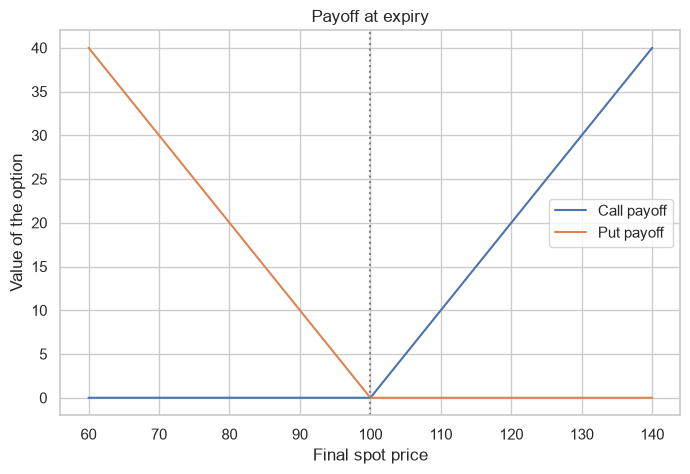

In [6]:
spots = np.linspace(60, 140, 161)
plt.figure(figsize=(8, 5))
plt.plot(spots, np.maximum(spots - K, 0), label="Call payoff")
plt.plot(spots, np.maximum(K - spots, 0), label="Put payoff")
plt.axvline(K, ls=":", color="grey")
plt.title("Payoff at expiry")
plt.xlabel("Final spot price")
plt.ylabel("Value of the option")
plt.legend()
plt.show()

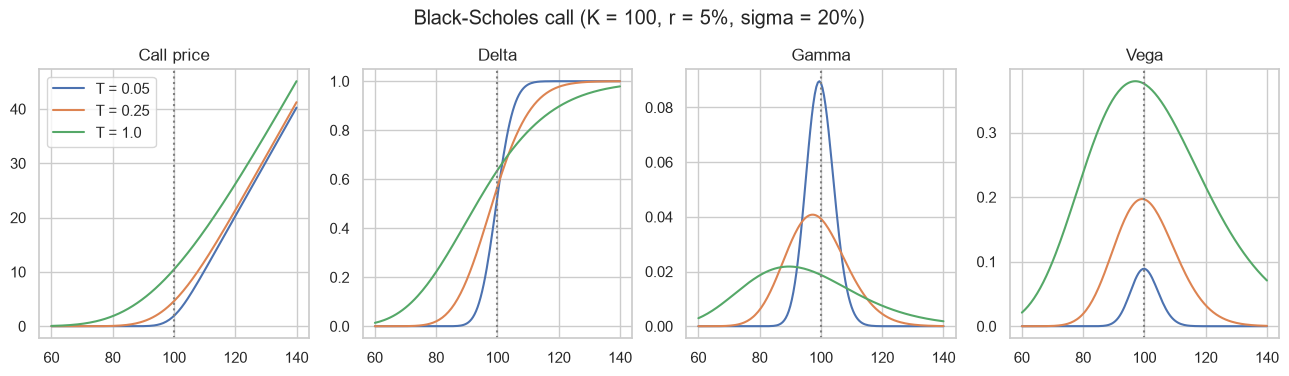

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for t in [0.05, 0.25, 1.0]:
    g = black_scholes_greeks(spots, K, t, r, sigma, "call")
    for ax, clave in zip(axes, ["price", "delta", "gamma", "vega"]):
        ax.plot(spots, g[clave], label=f"T = {t}")
for ax, titulo in zip(axes, ["Call price", "Delta", "Gamma", "Vega"]):
    ax.set_title(titulo)
    ax.axvline(K, ls=":", color="grey")
axes[0].legend()
plt.suptitle("Black-Scholes call (K = 100, r = 5%, sigma = 20%)", y=1.05)
plt.savefig("figures/greeks.png", bbox_inches="tight")
plt.show()

Gamma and vega are highest at the money, and near expiry gamma becomes very high and very concentrated around the strike.